In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

missing = df.isnull().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
print("\nMissing Values:\n", missing[missing["missing_count"] > 0])

print("\nNumeric Summary:\n", df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
           missing_count  missing_pct
Age                 177        19.87
Cabin               687        77.10
Embarked              2         0.22

Numeric Summary:
        PassengerId    Survived      Pclass         Age     

In [4]:
df_clean = df.copy()
df_clean["Age"] = df_clean["Age"].fillna(df_clean["Age"].median())
df_clean["Embarked"] = df_clean["Embarked"].fillna(df_clean["Embarked"].mode()[0])
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1
df_clean["IsAlone"] = (df_clean["FamilySize"] == 1).astype(int)

df_clean[["Age", "Embarked", "FamilySize", "IsAlone"]].head()

,Age,Embarked,FamilySize,IsAlone
0,22.0,S,2,0
1,38.0,C,2,0
2,26.0,S,1,1
3,35.0,S,2,0
4,35.0,S,1,1


In [5]:
print("Overall Survival Rate:", round(df_clean["Survived"].mean() * 100, 2), "%")

print("\nSurvival Rate by Sex (%):")
print((df_clean.groupby("Sex")["Survived"].mean() * 100).round(2))

print("\nStats by Passenger Class:")
print(
    df_clean.groupby("Pclass").agg(
        passengers=("Survived", "count"),
        survival_pct=("Survived", lambda s: round(s.mean() * 100, 2)),
        mean_fare=("Fare", "mean"),
        median_age=("Age", "median"),
    )
)

print("\nSurvival Rate by Sex & Pclass (%):")
print(
    (
        df_clean.pivot_table(
            values="Survived", index="Sex", columns="Pclass", aggfunc="mean"
        )
        * 100
    ).round(2)
)

Overall Survival Rate: 38.38 %

Survival Rate by Sex (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Stats by Passenger Class:
        passengers  survival_pct  mean_fare  median_age
Pclass                                                 
1              216         62.96  84.154687        35.0
2              184         47.28  20.662183        28.0
3              491         24.24  13.675550        28.0

Survival Rate by Sex & Pclass (%):
Pclass      1      2      3
Sex                        
female  96.81  92.11  50.00
male    36.89  15.74  13.54


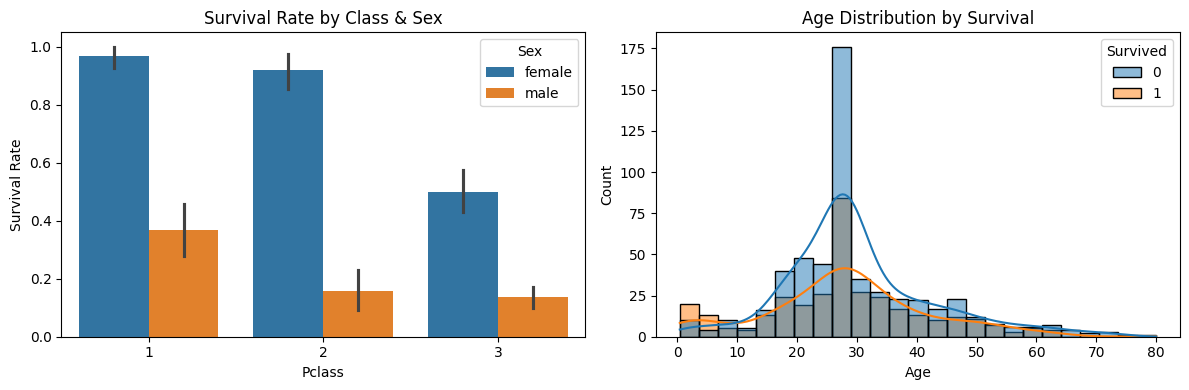

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df_clean, x="Pclass", y="Survived", hue="Sex", ax=axes[0])
axes[0].set_title("Survival Rate by Class & Sex")
axes[0].set_ylabel("Survival Rate")

sns.histplot(data=df_clean, x="Age", hue="Survived", bins=25, kde=True, ax=axes[1])
axes[1].set_title("Age Distribution by Survival")

plt.tight_layout()
plt.show()